<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 2000  Columns: 21
Phones in each price range: {0: 500, 1: 500, 2: 500, 3: 500} 

Train size: 1600  Test size: 400 

Epoch    1  Loss = 1.3863
Epoch 1000  Loss = 0.2143
Epoch 2000  Loss = 0.1647
Epoch 3000  Loss = 0.1418
Epoch 4000  Loss = 0.1278
Epoch 5000  Loss = 0.1180

Confusion Matrix (rows = actual, columns = predicted):
               Low (0)  Medium (1)  High (2)  Very high (3)
Low (0)             94           1         0              0
Medium (1)           5          98         2              0
High (2)             0           1       101              1
Very high (3)        0           0         0             97

Train accuracy: 98.12%
Test accuracy:  97.50%

Price range     Precision  Recall
Low (0)         0.95       0.99
Medium (1)      0.98       0.93
High (2)        0.98       0.98
Very high (3)   0.99       1.00

Top 5 features that decide the price range:
ram              46.33
battery_power    11.49
px_width          6.98
px_height         6.45
mobile_wt         1

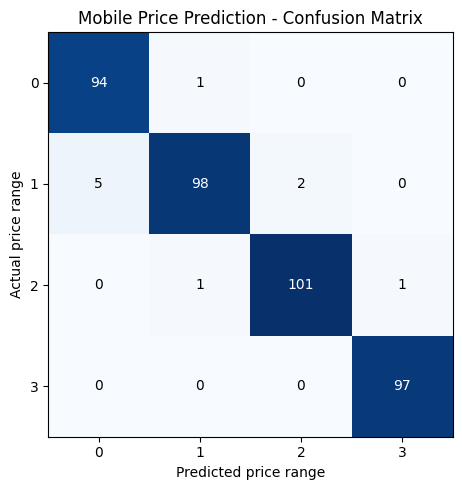

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Mobile Price Classification (Kaggle) - program17.csv, used as it is
# price_range: 0 = low cost, 1 = medium cost, 2 = high cost, 3 = very high cost

# ---- 1. Load CSV ----
df = pd.read_csv('program17.csv')
print("Rows:", len(df), " Columns:", df.shape[1])
labels = ['Low (0)', 'Medium (1)', 'High (2)', 'Very high (3)']
counts = df['price_range'].value_counts().sort_index()
print("Phones in each price range:", {int(k): int(v) for k, v in counts.items()}, "\n")

X_df = df.drop(columns='price_range')
X = X_df.values.astype(float)
y = df['price_range'].values
K = 4                                                    # number of price ranges

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]

# ---- 3. Standardize inputs (using training mean and std) ----
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
sd[sd == 0] = 1
Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 4. Softmax (multi-class logistic) regression with gradient descent ----
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

Y = np.eye(K)[ytr]                                       # one-hot labels
W = np.zeros((Xtr_s.shape[1], K))
b = np.zeros(K)
lr, epochs = 0.5, 5000

for epoch in range(1, epochs + 1):
    P = softmax(Xtr_s @ W + b)                           # probability of each price range
    loss = -np.mean(np.sum(Y * np.log(P + 1e-12), axis=1))
    W -= lr * Xtr_s.T @ (P - Y) / len(Xtr_s)             # gradient step
    b -= lr * np.mean(P - Y, axis=0)
    if epoch == 1 or epoch % 1000 == 0:
        print(f"Epoch {epoch:4d}  Loss = {loss:.4f}")

def predict(Xs):
    return softmax(Xs @ W + b).argmax(axis=1)

pred = predict(Xte_s)

# ---- 5. Confusion matrix ----
cm = np.zeros((K, K), dtype=int)
for a, p in zip(yte, pred):
    cm[a, p] += 1

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=labels, columns=labels))

# ---- 6. Accuracy, precision, recall ----
print(f"\nTrain accuracy: {np.mean(predict(Xtr_s) == ytr) * 100:.2f}%")
print(f"Test accuracy:  {np.trace(cm) / cm.sum() * 100:.2f}%")
print("\nPrice range     Precision  Recall")
for i, name in enumerate(labels):
    prec = cm[i, i] / cm[:, i].sum() if cm[:, i].sum() else 0
    rec = cm[i, i] / cm[i, :].sum() if cm[i, :].sum() else 0
    print(f"{name:<15} {prec:.2f}       {rec:.2f}")

# ---- 7. Which features decide the price range ----
importance = pd.Series(np.abs(W).sum(axis=1), index=X_df.columns).sort_values(ascending=False)
print("\nTop 5 features that decide the price range:")
print(importance.head(5).round(2).to_string())

# ---- 8. Predict the price range of a new phone ----
new = df.drop(columns='price_range').iloc[[0]].copy()    # start from the first phone
new['ram'] = 3500; new['battery_power'] = 1800; new['px_height'] = 1200; new['px_width'] = 1500
probs = softmax(((new.values.astype(float)) - mu) / sd @ W + b)[0]
print("\nNew phone: RAM 3500 MB, battery 1800 mAh, screen 1500 x 1200 pixels")
for name, p in zip(labels, probs):
    print(f"  P({name}) = {p:.3f}")
print("Predicted price range:", labels[probs.argmax()])

# ---- 9. Plot the confusion matrix ----
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(K)); ax.set_xticklabels(range(K))
ax.set_yticks(range(K)); ax.set_yticklabels(range(K))
ax.set_xlabel('Predicted price range'); ax.set_ylabel('Actual price range')
ax.set_title('Mobile Price Prediction - Confusion Matrix')
for i in range(K):
    for j in range(K):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()